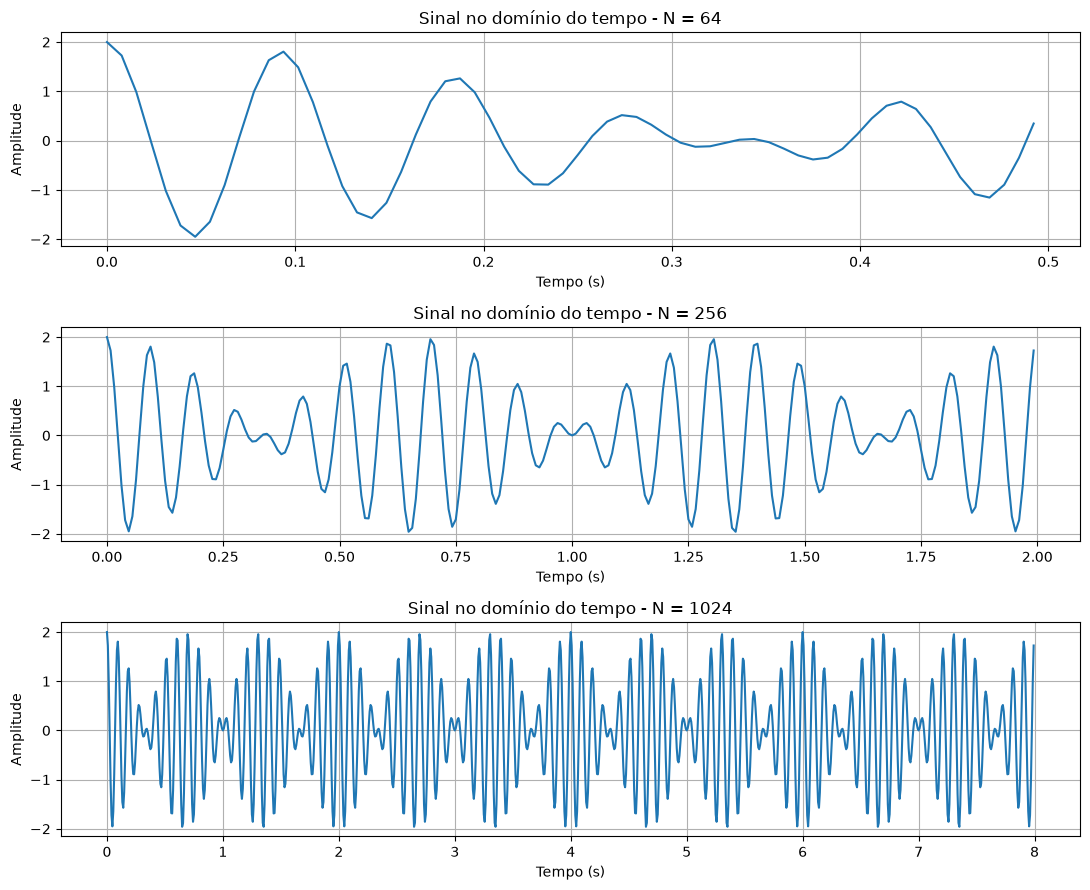

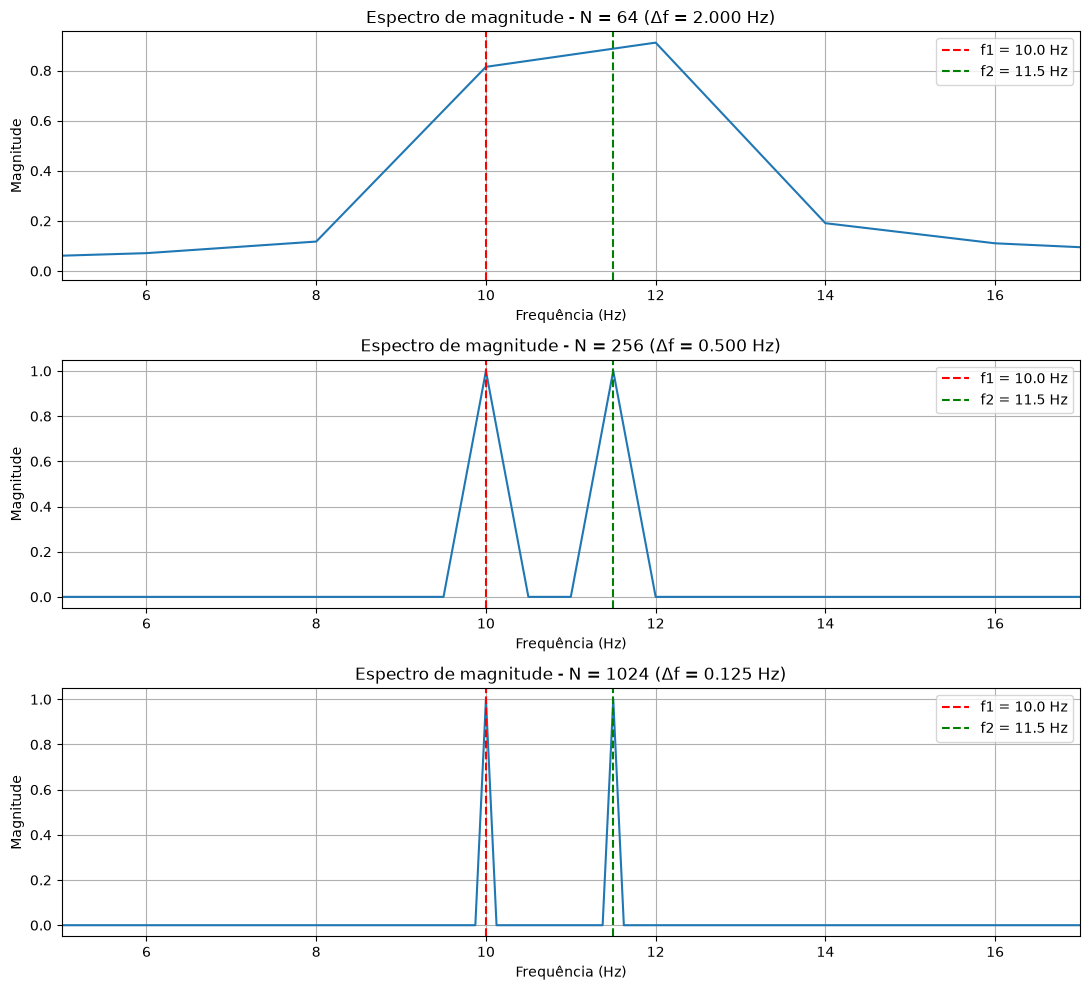

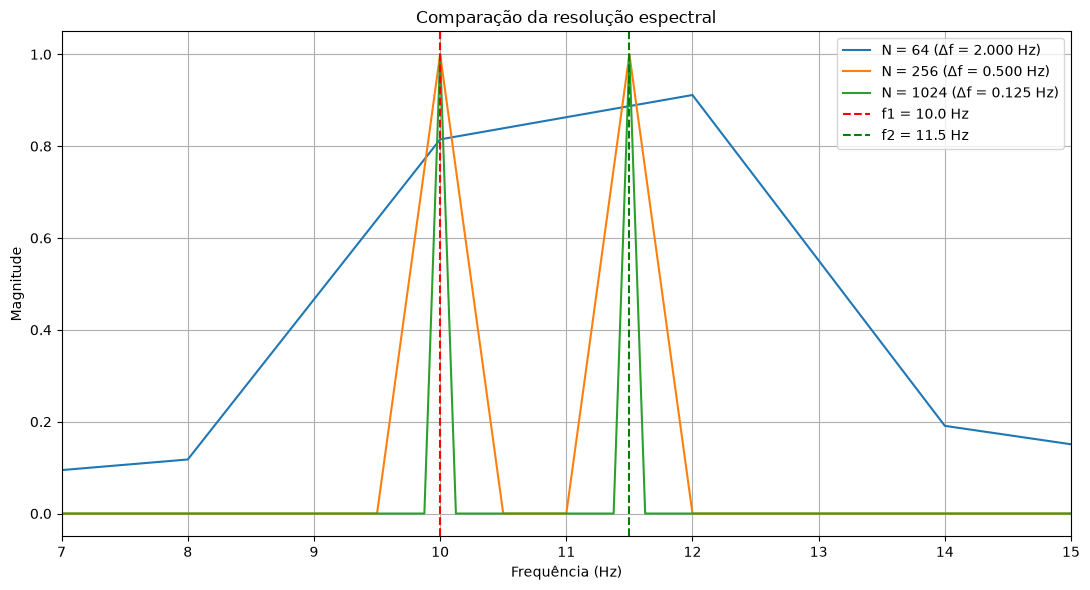

ANÁLISE DA RESOLUÇÃO ESPECTRAL

Número de amostras: 64
Frequência de amostragem: 128 Hz
Resolução espectral: 2.000 Hz
Duração da aquisição: 0.500 segundos
Resultado esperado: componentes difíceis de separar.

Número de amostras: 256
Frequência de amostragem: 128 Hz
Resolução espectral: 0.500 Hz
Duração da aquisição: 2.000 segundos
Resultado esperado: componentes mais facilmente separáveis.

Número de amostras: 1024
Frequência de amostragem: 128 Hz
Resolução espectral: 0.125 Hz
Duração da aquisição: 8.000 segundos
Resultado esperado: componentes mais facilmente separáveis.

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES GERAIS
# ============================================================

fs = 128                  # Frequência de amostragem (Hz)

# Frequências das duas senoides
f1 = 10.0                 # Hz
f2 = 11.5                 # Hz

# Amplitudes
A1 = 1.0
A2 = 1.0

# Quantidades de amostras a serem analisadas
valores_N = [64, 256, 1024]


# ============================================================
# 2. FUNÇÃO PARA GERAR O SINAL
# ============================================================

def gerar_sinal(N):

    n = np.arange(N)

    # Conversão dos índices em tempo (segundos)
    t = n / fs

    # Geração das senoides
    x1 = A1 * np.cos(2 * np.pi * f1 * t)
    x2 = A2 * np.cos(2 * np.pi * f2 * t)

    # Sinal composto
    x = x1 + x2

    return t, x


# ============================================================
# 3. FUNÇÃO PARA CALCULAR O ESPECTRO
# ============================================================

def calcular_espectro(x):

    N = len(x)

    # Cálculo da FFT
    X = np.fft.rfft(x)

    # Eixo de frequências
    frequencias = np.fft.rfftfreq(N, d=1/fs)

    # Magnitude normalizada
    magnitude = np.abs(X) / N

    # Correção para espectro de um lado
    if N % 2 == 0:
        magnitude[1:-1] *= 2
    else:
        magnitude[1:] *= 2

    return frequencias, magnitude


# ============================================================
# 4. VISUALIZAÇÃO DOS SINAIS NO DOMÍNIO DO TEMPO
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(11, 9))

for ax, N in zip(axes, valores_N):

    t, x = gerar_sinal(N)

    ax.plot(t, x)

    ax.set_title(f"Sinal no domínio do tempo - N = {N}")
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 5. COMPARAÇÃO DOS ESPECTROS DE MAGNITUDE
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(11, 10))

for ax, N in zip(axes, valores_N):

    t, x = gerar_sinal(N)

    frequencias, magnitude = calcular_espectro(x)

    # Resolução espectral
    delta_f = fs / N

    ax.plot(frequencias, magnitude)

    # Identificação das frequências originais
    ax.axvline(f1, color='red', linestyle='--',
               label=f"f1 = {f1} Hz")

    ax.axvline(f2, color='green', linestyle='--',
               label=f"f2 = {f2} Hz")

    # Limitação da visualização para facilitar a análise
    ax.set_xlim(5, 17)

    ax.set_title(
        f"Espectro de magnitude - N = {N} "
        f"(Δf = {delta_f:.3f} Hz)"
    )

    ax.set_xlabel("Frequência (Hz)")
    ax.set_ylabel("Magnitude")

    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 6. COMPARAÇÃO DOS TRÊS ESPECTROS NO MESMO GRÁFICO
# ============================================================

plt.figure(figsize=(11, 6))

for N in valores_N:

    t, x = gerar_sinal(N)

    frequencias, magnitude = calcular_espectro(x)

    plt.plot(
        frequencias,
        magnitude,
        label=f"N = {N} (Δf = {fs/N:.3f} Hz)"
    )

plt.axvline(f1, color='red', linestyle='--',
            label=f"f1 = {f1} Hz")

plt.axvline(f2, color='green', linestyle='--',
            label=f"f2 = {f2} Hz")

plt.xlim(7, 15)

plt.title("Comparação da resolução espectral")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. RELATÓRIO DOS PARÂMETROS
# ============================================================

print("ANÁLISE DA RESOLUÇÃO ESPECTRAL")
print("=" * 55)

for N in valores_N:

    delta_f = fs / N
    duracao = N / fs

    print(f"\nNúmero de amostras: {N}")
    print(f"Frequência de amostragem: {fs} Hz")
    print(f"Resolução espectral: {delta_f:.3f} Hz")
    print(f"Duração da aquisição: {duracao:.3f} segundos")

    if delta_f > abs(f2 - f1):
        print("Resultado esperado: componentes difíceis de separar.")

    elif delta_f == abs(f2 - f1):
        print("Resultado esperado: componentes no limite de resolução.")

    else:
        print("Resultado esperado: componentes mais facilmente separáveis.")


print("\nSimulação concluída!")
